# Workers and the work calendar

Instance `data/instances/toy-workshop.json` (model in `math/04_workers.md`): a printer, an oven and a mill, two
workers A and B, the default calendar (shift 08:00–17:30, break of 60 minutes starting 12:00–13:00, up to 120
minutes of overtime, shipping cutoff 12:00, Monday to Friday; t = 0 is Monday 08:00). Eight orders with due dates at
the Monday or Tuesday cutoff. Worker shares:
- print and mill: the loading (prefix) by a worker, the rest unattended; a print may run into the night;
- oven: loading and removal (prefix and suffix); the only operation with a pending removal (C7$^o$);
- Gegenbetten of k3: 30 minutes by a worker, then the rest without a worker (unattended rest);
- QM: the whole operation, only by A; packing: the whole operation, by A or B.

k7 (QM released 15:30) and k8 (QM released Tuesday 08:00) are both due Tuesday 12:00 and both need A: k7's QM
either runs into overtime on Monday or one of the two misses Tuesday's cutoff. **A hand-made toy instance, not
Fidentis data.**

In [1]:
%matplotlib inline
from fractions import Fraction
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

import simulation
from simulation.check.feasibility import check_schedule
from simulation.control.rescheduling import ReschedulingPolicy, execute
from simulation.io.json_loader import read_model
from simulation.metrics import run_metrics
from simulation.model.compiled import compile_instance
from simulation.model.instance import Instance
from simulation.objectives import ACTIVE_MAKESPAN, BREAK_PENALTY, MAKESPAN, TOTAL_TARDINESS, overtime, worker_objective
from simulation.planners.cpsat import cpsat_planner, solve
from simulation.planners.dispatching import ASSIGNMENT_RULES, SEQUENCING_RULES, dispatch_plan, dispatch_planner
from simulation.sim.scenario import sample_scenario
from simulation.viz import plot_days, plot_shifts

DATA = Path(simulation.__file__).parents[2] / "data"
inst = read_model(DATA / "instances" / "toy-workshop.json", Instance)
ci = compile_instance(inst)
THETA = Fraction(1, 60)  # 60 minutes of overtime are worth one day late
objective = worker_objective(THETA)

## Plans

The worker objective (`math/04_workers.md` (O4)–(O6)), lexicographic: (1) days late + $\theta_O$ × overtime minutes,
$\theta_O = 1/60$; (2) break postponement and spread; (3) the activity clock $C^{act}_{\max}$ (time in the shifts,
plus time outside them while an operation is in progress). Best of the 15 dispatching rules under this objective
against CP-SAT (level by level, 20 s per level).

In [2]:
rules = {f"{s}/{a or 'joint'}": dispatch_plan(ci, SEQUENCING_RULES[s], ASSIGNMENT_RULES[a] if a else None)
         for s in SEQUENCING_RULES for a in [*ASSIGNMENT_RULES, None]}
rule = min(rules, key=lambda name: objective.evaluate(ci, rules[name].assignments, rules[name].breaks))
rule_plan = rules[rule]
cp = solve(ci, objective, time_limit=20, workers=8)
print(f"CP-SAT: {cp.status}, level values {cp.levels}, {cp.wall_time:.1f} s")
print(f"{'plan':30} {'days late':>9} {'overtime':>9} {'breaks':>7} {'Cmax':>6} {'C_act':>6} {'violations':>11}")
for name, schedule, breaks in [(f"best rule ({rule})", rule_plan.assignments, rule_plan.breaks),
                               ("CP-SAT", cp.schedule, cp.breaks)]:
    print(f"{name:30} {TOTAL_TARDINESS.evaluate(ci, schedule):>9} {overtime(ci, schedule):>9}"
          f" {BREAK_PENALTY.evaluate(ci, schedule, breaks):>7} {MAKESPAN.evaluate(ci, schedule):>6}"
          f" {ACTIVE_MAKESPAN.evaluate(ci, schedule):>6} {len(check_schedule(ci, schedule, breaks=breaks)):>11}")

CP-SAT: OPTIMAL, level values (30, 0, 920), 0.1 s
plan                           days late  overtime  breaks   Cmax  C_act  violations
best rule (mwkr/least_load)            1         0       0   1910   1190           0
CP-SAT                                 0        30       0   1640    920           0


### Resources (machines, workers, unattended rest)

One row per machine and worker, and a row "rest" for the unattended time of machine-less operations. A machine bar is
outlined (unattended) with the worker time in its lower half. Colors encode the state: attended, unattended,
overtime, break; nights and days off are hatched and squeezed to 60 minutes (also while a print runs through the
night), the overtime window 17:30–19:30 is tinted, the cutoffs are dashed. First the rule plan, then CP-SAT.

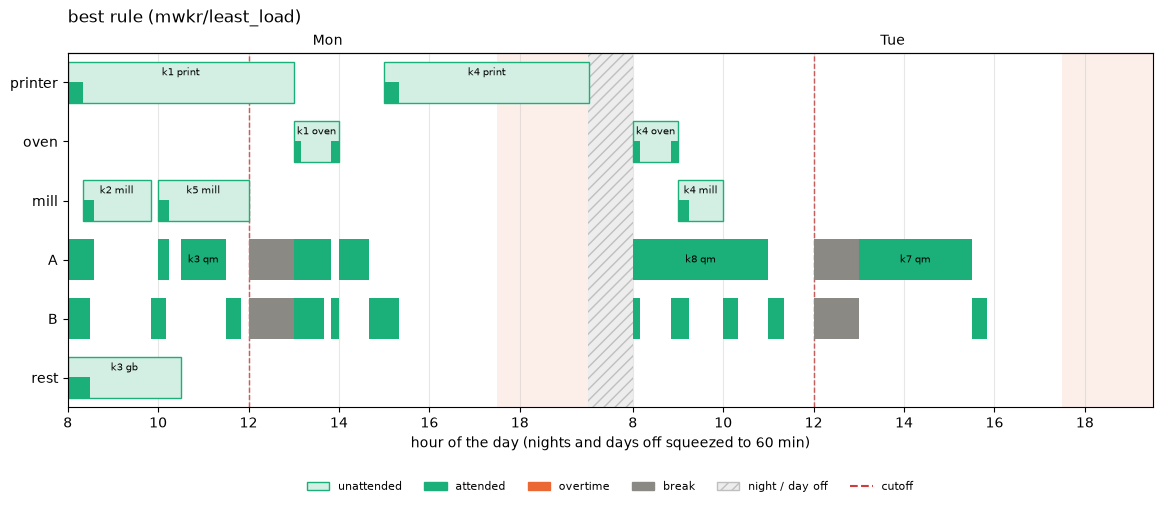

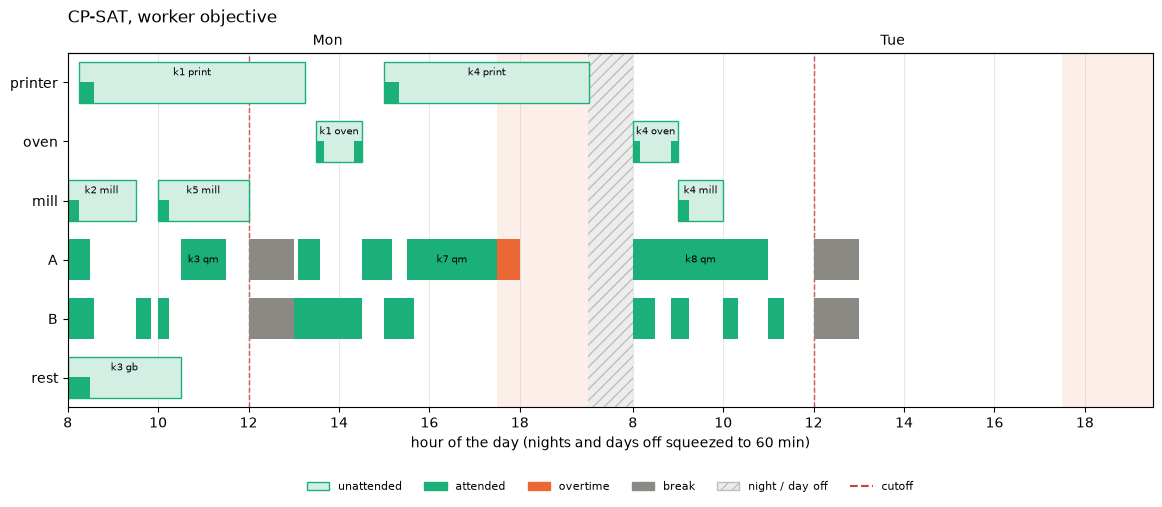

In [3]:
for title, schedule, breaks in [(f"best rule ({rule})", rule_plan.assignments, rule_plan.breaks),
                                ("CP-SAT, worker objective", cp.schedule, cp.breaks)]:
    plot_shifts(ci, schedule, breaks, title=title)
    plt.show()

### Workers only, colored by machine

Each bar is one share of a worker, labeled order, operation and machine. The color names the machine the share
serves (printer, oven, mill), light grey with an outline is work without a machine (QM, packing, Gegenbetten);
overtime is cross-hatched. Unattended machine time is not shown here. Three hues only: coloring by step (six here)
fails the colorblind check of the dataviz validator for neighboring bars, three pass it (`viz.MACHINE_COLORS`).

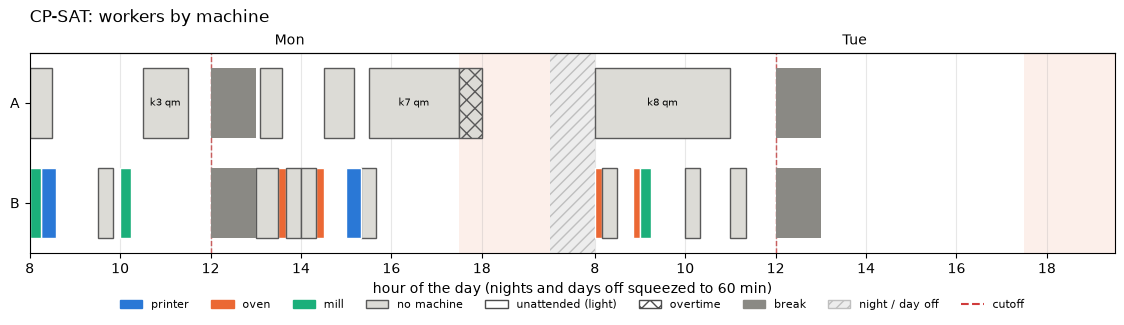

In [4]:
plot_shifts(ci, cp.schedule, cp.breaks, rows="workers", color_by="machine", title="CP-SAT: workers by machine")
plt.show()

### Orders

One row per order: its path through the days, each operation labeled with its workers.

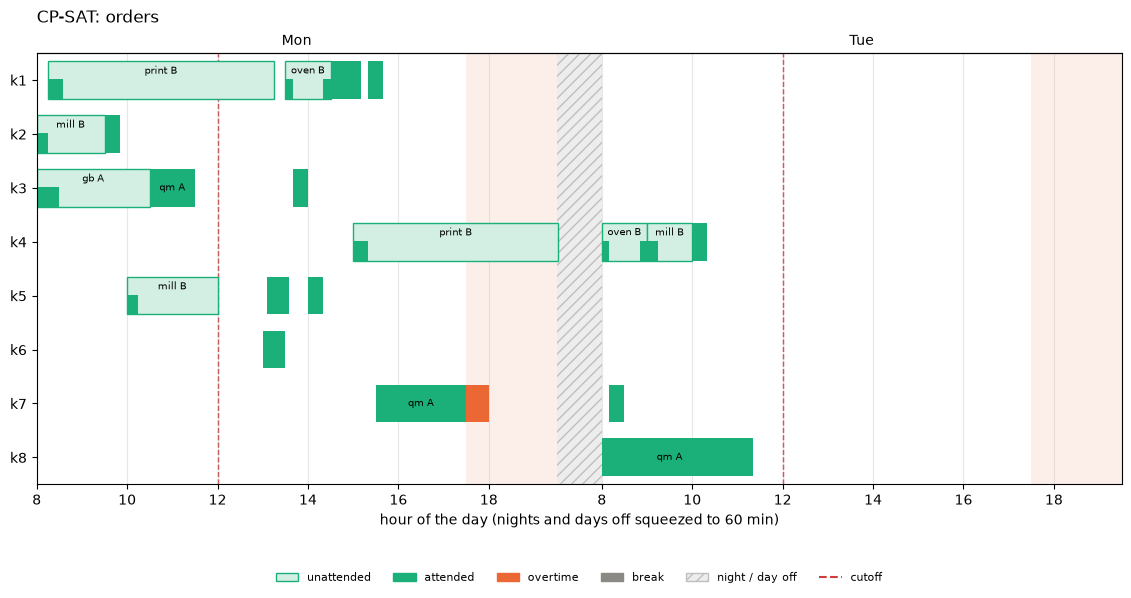

In [5]:
plot_shifts(ci, cp.schedule, cp.breaks, rows="orders", title="CP-SAT: orders")
plt.show()

### Calendar view, three days

One column per day, time of day downward; 08:00–19:30 to scale, the time before and after squeezed to 30 minutes
each. CP-SAT books a break for every working day of its horizon, so Wednesday shows only the breaks.

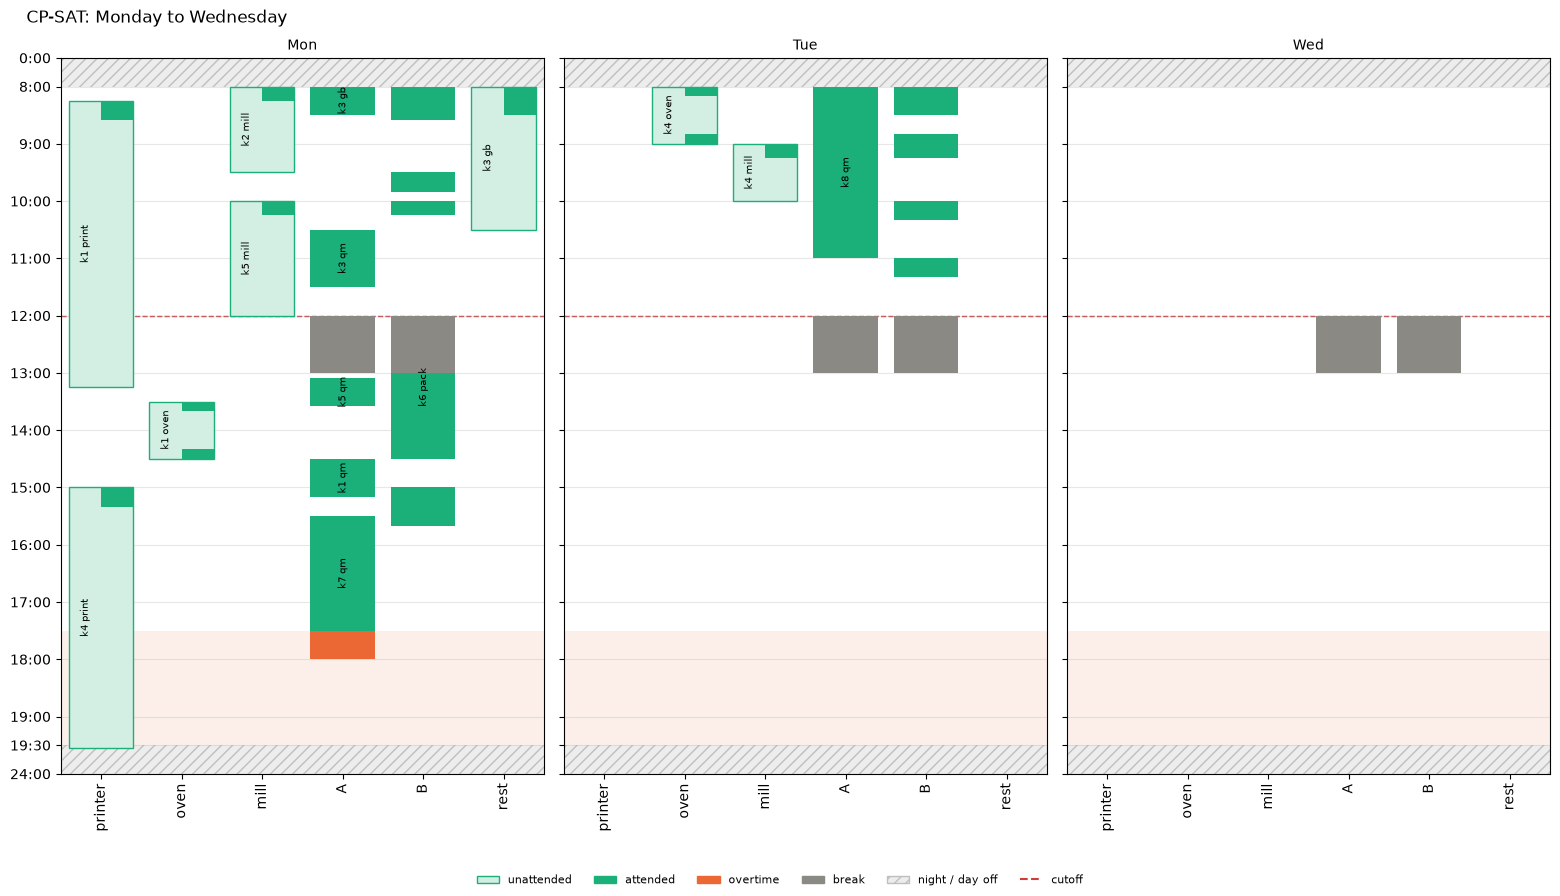

In [6]:
plot_days(ci, cp.schedule, cp.breaks, days=3, title="CP-SAT: Monday to Wednesday")
plt.show()

## Trade-off between overtime and days late ($\theta_O$)

A smaller instance with one exact threshold (the chain of `tests/test_worker_objective.py`): one worker, operation
A (240 minutes) from Monday 15:00, then B (240), due Tuesday 12:00. With 90 minutes of overtime A ends at 19:00 and B
runs Tuesday 08:00–12:00 (on time); without, A runs Tuesday morning and B after the break (one day late). Level 1
weighs one day late against $1/\theta_O$ minutes of overtime: below 90 the plan is late, above 90 it works overtime,
at exactly 90 both have the same value (a tie: the solver may return either). CP-SAT per value of $1/\theta_O$.

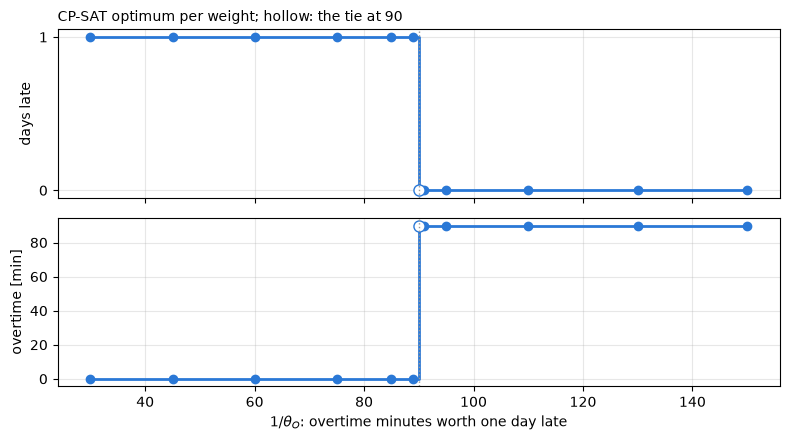

In [7]:
chain = compile_instance(Instance.model_validate({
    "schema_version": "0.6", "name": "chain", "machines": ["M"], "workers": ["W1"], "calendar": {},
    "orders": [{"id": "K", "release": 420, "due_date": 1680, "operations": [
        {"id": "A", "step": "s", "duration": 240, "worker": {"whole": True}},
        {"id": "B", "step": "s", "duration": 240, "worker": {"whole": True}, "predecessors": ["A"]}]}]}))
minutes_per_day = [30, 45, 60, 75, 85, 89, 90, 91, 95, 110, 130, 150]
late, extra = [], []
for m in minutes_per_day:
    r = solve(chain, worker_objective(Fraction(1, m)), time_limit=10, workers=1)
    assert r.status == "OPTIMAL" and check_schedule(chain, r.schedule, breaks=r.breaks) == []
    late.append(TOTAL_TARDINESS.evaluate(chain, r.schedule))
    extra.append(overtime(chain, r.schedule))

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
for ax, values, label in [(top, late, "days late"), (bottom, extra, "overtime [min]")]:
    ax.step(minutes_per_day, values, where="post", color="#2a78d6", linewidth=2)
    ax.plot([m for m in minutes_per_day if m != 90], [v for m, v in zip(minutes_per_day, values, strict=False) if m != 90],
            "o", color="#2a78d6", markersize=6)
    tie = values[minutes_per_day.index(90)]
    ax.plot([90], [tie], "o", markerfacecolor="white", markeredgecolor="#2a78d6", markersize=8)
    ax.axvline(90, color="0.6", linestyle=":", linewidth=1)
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
top.set_yticks([0, 1])
top.set_title("CP-SAT optimum per weight; hollow: the tie at 90", loc="left", fontsize=10)
bottom.set_xlabel(r"$1/\theta_O$: overtime minutes worth one day late")
plt.tight_layout()
plt.show()

## Execution under disturbances

Durations log-normal ($\sigma = 0.3$), start offsets ($q = 0.5$, $a = b = 5$), seeds 0–9. Start plan: the CP-SAT
plan with its breaks. Policies: no planning tool, repair only, complete rescheduling with the best rule and with
CP-SAT (worker objective, 2 s per level), each triggered by $\delta_C = 10$, $\delta_S = 30$ and a safety net every
120 minutes (as in notebook 05); CP-SAT also with a safety net every 15 minutes. One instance, no statistical test.

Days late are whole days per run (missed cutoffs), so the table gives them as totals over the 10 runs, with the
number of runs that are late at all, and the level-1 value of the worker objective, days late + $\theta_O$ ×
overtime minutes, also summed. The other columns are means per run: makespan $C_{\max}$, activity clock $C^{act}$,
total tardiness $\sum T$ in minutes, then the worker metrics (`math/23_metrics.md`): overtime minutes, overruns past
the overtime window, oven overstay minutes, break postponement and spread, swaps by the factory; $N_C$
reschedulings. "feasible": every realized schedule passes the checker up to C2 (realized durations) and C14 (a break
realized after 13:00, forced by an overrun).

In [8]:
start = cp.schedule
scenarios = [sample_scenario(inst, sigma=0.3, seed=seed, q=0.5, max_early=5, max_late=5) for seed in range(10)]
s, a = rule.split("/")
TRIGGERS = {"max_makespan_change": 10, "max_shift": 30, "period": 120}
policies = {
    "no planning tool": None,
    "repair only": ReschedulingPolicy(),
    f"rule rescheduling ({rule})": ReschedulingPolicy(
        dispatch_planner(SEQUENCING_RULES[s], ASSIGNMENT_RULES.get(a)), **TRIGGERS),
    "CP-SAT rescheduling": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=objective), **TRIGGERS),
    "CP-SAT rescheduling, every 15 min": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=objective),
                                                            **(TRIGGERS | {"period": 15})),
}
means = {"makespan": "Cmax", "active_makespan": "C_act", "total_tardiness": "sum T", "overtime": "overtime",
         "overruns": "overruns", "overstay": "overstay", "break_postponement": "brk post", "break_spread": "spread",
         "swaps": "swaps", "reschedulings": "N_C"}
results = {}
print(f"{'policy':36}{'days':>6}{'late runs':>10}{'level 1':>9}" + "".join(f"{c:>9}" for c in means.values())
      + f"{'feasible':>10}")
for name, policy in policies.items():
    results[name] = [execute(ci, start, sc, policy, breaks=cp.breaks) for sc in scenarios]
    rows = [run_metrics(ci, start, r) for r in results[name]]
    ok = all({v.constraint for v in check_schedule(ci, r.schedule, breaks=r.breaks)} <= {"C2", "C14"}
             for r in results[name])
    days = [r["tardy_days"] for r in rows]
    level_1 = sum(d + THETA * r["overtime"] for d, r in zip(days, rows, strict=True))
    print(f"{name:36}{sum(days):>6}{sum(d > 0 for d in days):>10}{float(level_1):>9.2f}"
          + "".join(f"{mean(r[k] for r in rows):>9.1f}" for k in means) + f"{str(ok):>10}")
    print(f"{'':36}days per run: {days}")

policy                                days late runs  level 1     Cmax    C_act    sum T overtime overruns overstay brk post   spread    swaps      N_C  feasible
no planning tool                         2         2     8.63   1674.3    982.5     21.0     39.8      0.0      8.9     13.6     13.6      1.4      0.0      True
                                    days per run: [0, 0, 1, 1, 0, 0, 0, 0, 0, 0]


repair only                              9         4    12.72   1862.0   1054.0    277.8     22.3      0.0      1.0      5.7      5.7      1.3      0.0      True
                                    days per run: [0, 2, 4, 1, 0, 2, 0, 0, 0, 0]


rule rescheduling (mwkr/least_load)     13        10    14.27   1895.8   1192.4    251.6      7.6      0.0      0.0      7.4      7.4      0.2     18.0      True
                                    days per run: [1, 1, 3, 2, 1, 1, 1, 1, 1, 1]


CP-SAT rescheduling                      6         4     9.55   1686.5    986.2     51.4     21.3      0.0      3.2     11.4      7.6      0.8     17.9      True
                                    days per run: [0, 2, 2, 1, 0, 1, 0, 0, 0, 0]


CP-SAT rescheduling, every 15 min        4         3     7.55   1673.0    972.2     40.6     21.3      0.0      1.7      9.8      9.2      0.8    113.1      True
                                    days per run: [0, 1, 2, 1, 0, 0, 0, 0, 0, 0]


### One realized run

Seed 0 with CP-SAT rescheduling: the realized schedule and the realized breaks.

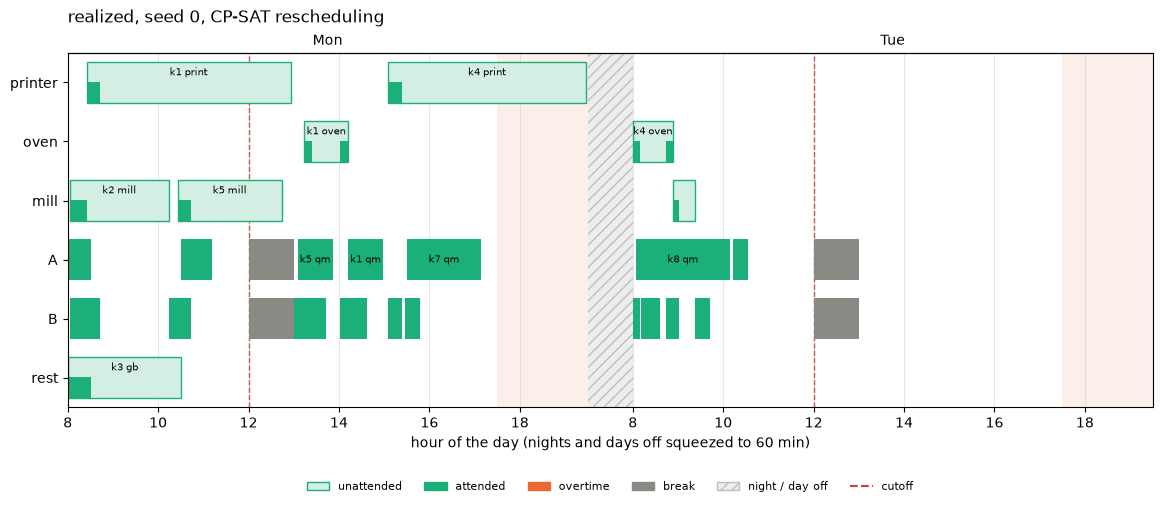

In [9]:
run = results["CP-SAT rescheduling"][0]
plot_shifts(ci, run.schedule, run.breaks, title="realized, seed 0, CP-SAT rescheduling")
plt.show()

**Observations** (one toy instance, 10 seeds; own computation, no statistical test):

- **Plans:** CP-SAT books 30 minutes of overtime on Monday (A's QM of k7 until 18:00) and is on time; the best rule
  (MWKR + least load) books no overtime, so k7's QM runs Tuesday after the break and misses Tuesday's cutoff (1 day
  late). With $\theta_O = 1/60$ the 30 minutes are worth half a day: CP-SAT's choice. The activity clock is 920
  against 1190 minutes; the nights do not count while nothing runs.
- **Trade-off:** on the chain the optimum switches from one day late to 90 minutes of overtime between
  $1/\theta_O = 89$ and $91$; at exactly 90 both plans have the same level-1 value and CP-SAT returned the overtime
  plan.
- **Execution:** see the table for the numbers. Without a planning tool the factory starts every operation as soon
  as predecessors, machine and a worker allow, in the planned order, and uses overtime up to the window; it misses
  few cutoffs but works the most overtime. Repair adds no overtime beyond the plan's (`math/05`, repair with the
  calendar): a share that no longer fits moves to the next morning. In a scratch run (not in the repo) a repair that
  may use overtime up to the window had 3 days late instead of 9 (overtime 434 instead of 223 minutes in total), but
  CP-SAT rescheduling on top of it did not change (6 days): for CP-SAT the repair between the replans is not the
  cause. Replanning every 15 minutes instead of 120 lowers CP-SAT's days late and gives the lowest level-1 value. The
  rule plans almost no overtime and is late in most runs.
- All realized schedules pass the checker up to C2 and C14; overruns past the overtime window do not occur; oven
  overstays are rare and short.